# Dia 29 — Fundamentos de EDA (Exploratory Data Analysis)

**Fase 2 — EDA (Dia 1 de 28)** · 28/11/2026 · Gutemberg Rapôso

Este é o **primeiro caderno da Fase 2**. Depois de 28 dias consolidando Python, pandas, visualização e boas práticas de engenharia, começo agora a usar essas ferramentas para *fazer perguntas aos dados*. O dataset escolhido é o clássico **Titanic** (`seaborn.load_dataset('titanic')`), pequeno o suficiente para inspecionar linha a linha e rico o suficiente para mostrar dados ausentes, variáveis mistas e relações não triviais.

### Roteiro
1. Introdução ao EDA e CRISP-DM
2. Carregamento e inspeção inicial
3. Análise de valores ausentes (MCAR, MAR, MNAR)
4. Análise univariada
5. Análise bivariada
6. Visualizações avançadas
7. Insights e conclusões

> **Escopo honesto:** este caderno é descritivo. As associações observadas não são testadas estatisticamente aqui (isso é tema da Fase 3) e não implicam causalidade.

## 1. Introdução ao EDA

### O que é EDA?
**Análise Exploratória de Dados** é a etapa em que examinamos um conjunto de dados *antes* de modelá-lo, combinando estatísticas descritivas e gráficos para entender sua estrutura. O termo foi popularizado por **John Tukey** (1977), que defendia "olhar os dados" antes de testar hipóteses formais.

### Por que é fundamental?
- **Qualidade dos dados:** encontrar valores ausentes, duplicados, tipos errados e outliers antes que contaminem um modelo.
- **Entendimento do domínio:** cada coluna representa algo do mundo real; o EDA revela se os dados fazem sentido.
- **Formulação de hipóteses:** padrões visuais sugerem perguntas que depois serão testadas.
- **Decisões de modelagem:** distribuições assimétricas, correlações fortes e classes desbalanceadas influenciam a escolha de transformações e algoritmos.

> 💡 **Nota de aprendizado:** na Linguística, antes de propor uma regra variável, o pesquisador observa o *corpus* — frequências, contextos, falantes. O EDA cumpre o mesmo papel: é a "leitura atenta" dos dados antes da teoria.

### Onde o EDA se encaixa no CRISP-DM

O **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*) organiza um projeto de dados em seis fases cíclicas:

| # | Fase | Papel do EDA |
|---|------|--------------|
| 1 | Entendimento do negócio | Traduzir o problema em perguntas que os dados podem responder |
| 2 | **Entendimento dos dados** | **Núcleo do EDA:** coletar, descrever, explorar e verificar qualidade |
| 3 | **Preparação dos dados** | EDA orienta limpeza, imputação e *feature engineering* |
| 4 | Modelagem | Hipóteses do EDA guiam a escolha de variáveis e algoritmos |
| 5 | Avaliação | EDA dos erros do modelo (análise de resíduos) |
| 6 | Implantação | EDA contínuo para monitorar *drift* |

O processo não é linear: é comum voltar da modelagem para o EDA quando um resultado parece estranho.

### Perguntas que o EDA responde

1. **Estrutura:** quantas linhas e colunas? Quais tipos de dados?
2. **Qualidade:** há valores ausentes, duplicados ou impossíveis?
3. **Distribuição:** como cada variável se distribui? É simétrica? Tem outliers?
4. **Relações:** quais variáveis se associam entre si e com a variável-alvo?
5. **Redundância:** existem colunas que codificam a mesma informação?
6. **Próximos passos:** que transformações e hipóteses merecem investigação?

No Titanic, a pergunta orientadora será: **quais características dos passageiros estão associadas à sobrevivência?**

## 2. Carregamento e Inspeção Inicial

In [1]:
# Core libraries for the whole notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Display and plotting defaults
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 2.3.3 | numpy 1.26.4 | seaborn 0.13.2


In [2]:
# Load the Titanic dataset bundled with seaborn (public, 891 passengers)
df = sns.load_dataset("titanic")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Shape: 891 rows x 15 columns


In [3]:
# Column data types
df.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [4]:
# Full structural summary: non-null counts, dtypes and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
# First rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
# Last rows
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


> 💡 **Nota de aprendizado:** o dataset do seaborn tem **15 colunas**, algumas redundantes por construção:
> - `survived` (0/1) e `alive` ("no"/"yes") são a mesma informação;
> - `pclass` (1/2/3) e `class` ("First"/"Second"/"Third");
> - `embarked` (S/C/Q) e `embark_town`;
> - `who`, `adult_male` e `alone` são **derivadas** de `sex`, `age`, `sibsp` e `parch`.
>
> Identificar redundância é um resultado de EDA: se uma dessas colunas entrasse num modelo junto com o alvo (`alive`), teríamos **vazamento de dados** (*data leakage*).

In [7]:
# Descriptive statistics for numeric variables
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


In [8]:
# Descriptive statistics for categorical / object / boolean variables
df.describe(include=["object", "category", "bool"]).T

,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537


In [9]:
# Number of unique values per column, plus a sample of those values
unique_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "sample_values": [df[c].dropna().unique()[:5].tolist() for c in df.columns],
}).sort_values("n_unique")
unique_summary

,dtype,n_unique,sample_values
survived,int64,2,"[0, 1]"
sex,object,2,"[male, female]"
alive,object,2,"[no, yes]"
adult_male,bool,2,"[True, False]"
alone,bool,2,"[False, True]"
class,category,3,"[Third, First, Second]"
pclass,int64,3,"[3, 1, 2]"
embarked,object,3,"[S, C, Q]"
embark_town,object,3,"[Southampton, Cherbourg, Queenstown]"
who,object,3,"[man, woman, child]"


In [10]:
# Verify the redundancy claims programmatically
checks = {
    "survived == (alive == 'yes')": (df["survived"] == (df["alive"] == "yes").astype(int)).all(),
    "pclass <-> class one-to-one": df.groupby("pclass", observed=True)["class"].nunique().eq(1).all(),
    "embarked <-> embark_town one-to-one": df.dropna(subset=["embarked"]).groupby("embarked")["embark_town"].nunique().eq(1).all(),
    "alone == (sibsp + parch == 0)": (df["alone"] == ((df["sibsp"] + df["parch"]) == 0)).all(),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'FAIL'} {name}")

print(f"\nDuplicated rows: {df.duplicated().sum()}")

OK  survived == (alive == 'yes')
OK  pclass <-> class one-to-one
OK  embarked <-> embark_town one-to-one
OK  alone == (sibsp + parch == 0)

Duplicated rows: 107


> 💡 **Nota de aprendizado:** o dataset tem linhas duplicadas porque **não há coluna de identificação** (nome ou número do bilhete foram removidos nessa versão). Passageiros diferentes com os mesmos atributos aparecem como "duplicados". Por isso **não** removo essas linhas: duplicação só é erro quando sabemos que representa o mesmo registro.

## 3. Análise de Valores Ausentes

In [11]:
# Absolute and relative count of missing values per column
missing = pd.DataFrame({
    "n_missing": df.isnull().sum(),
    "pct_missing": (df.isnull().mean() * 100).round(2),
}).query("n_missing > 0").sort_values("n_missing", ascending=False)
missing

,n_missing,pct_missing
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


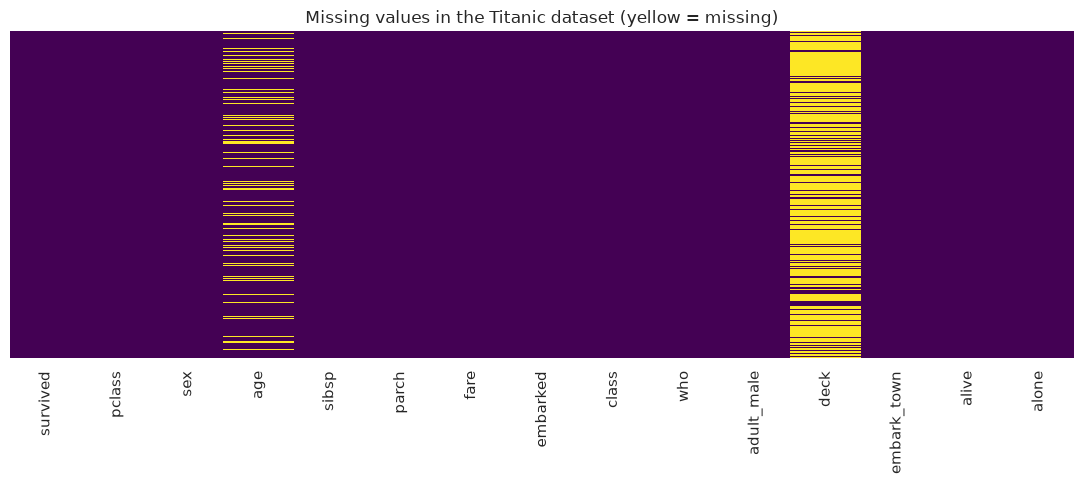

In [12]:
# Missing-value heatmap: each yellow stripe is a missing cell
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing values in the Titanic dataset (yellow = missing)")
plt.tight_layout()
plt.show()

In [13]:
# Is missingness in 'age' related to other variables? (hint for MAR vs MCAR)
age_missing = df["age"].isnull()
print("Share of missing 'age' by class:")
print(df.groupby("class", observed=True)["age"].apply(lambda s: s.isnull().mean()).round(3))
print("\nSurvival rate when age is missing vs present:")
print(df.groupby(age_missing)["survived"].mean().rename({False: "age present", True: "age missing"}).round(3))
print("\nShare of missing 'deck' by class:")
print(df.groupby("class", observed=True)["deck"].apply(lambda s: s.isnull().mean()).round(3))

Share of missing 'age' by class:
class
First     0.139
Second    0.060
Third     0.277
Name: age, dtype: float64

Survival rate when age is missing vs present:
age
age present    0.406
age missing    0.294
Name: survived, dtype: float64

Share of missing 'deck' by class:
class
First     0.190
Second    0.913
Third     0.976
Name: deck, dtype: float64


### Mecanismos de dados ausentes: MCAR, MAR e MNAR

A classificação de **Rubin (1976)** ajuda a decidir *como* tratar valores ausentes:

| Mecanismo | Definição | Exemplo no Titanic | Estratégia típica |
|-----------|-----------|--------------------|-------------------|
| **MCAR** — *Missing Completely At Random* | A ausência não depende de nenhuma variável | Uma página do registro perdida por acaso | Remoção de linhas é aceitável (perde-se poder, não se cria viés) |
| **MAR** — *Missing At Random* | A ausência depende de variáveis **observadas** | `age` falta mais na 3ª classe (≈28%) do que na 1ª (≈14%) e na 2ª (≈6%) | Imputação condicional (ex.: mediana por classe e sexo), imputação múltipla |
| **MNAR** — *Missing Not At Random* | A ausência depende do **próprio valor ausente** ou de algo não observado | `deck` falta para ≈98% da 3ª classe: cabines de 3ª classe raramente eram registradas | Modelar o mecanismo, criar indicador "ausente", coletar mais dados |

**Observações deste dataset:**
- **`deck` (~77% ausente):** imputar seria inventar informação. A ausência em si carrega significado (associada à classe), então uma opção é criar a categoria `"Unknown"` ou a flag `has_deck`.
- **`age` (~20% ausente):** padrão compatível com **MAR** em relação à classe — a imputação por grupo é mais defensável que a média global. Note também que a taxa de sobrevivência é menor quando `age` falta.
- **`embarked` / `embark_town` (2 linhas):** volume desprezível; imputar pela moda ou remover tem impacto mínimo.

> ⚠️ **Limite:** não é possível *provar* MCAR vs MAR vs MNAR apenas olhando os dados observados; os testes e gráficos dão **indícios**, e a decisão final exige conhecimento do domínio (como os registros foram coletados).

## 4. Análise Univariada

In [14]:
# Separate numeric and categorical columns for the univariate analysis
numeric_cols = ["age", "fare", "sibsp", "parch"]
categorical_cols = ["survived", "pclass", "sex", "embarked", "who", "deck", "alone"]
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

Numeric: ['age', 'fare', 'sibsp', 'parch']
Categorical: ['survived', 'pclass', 'sex', 'embarked', 'who', 'deck', 'alone']


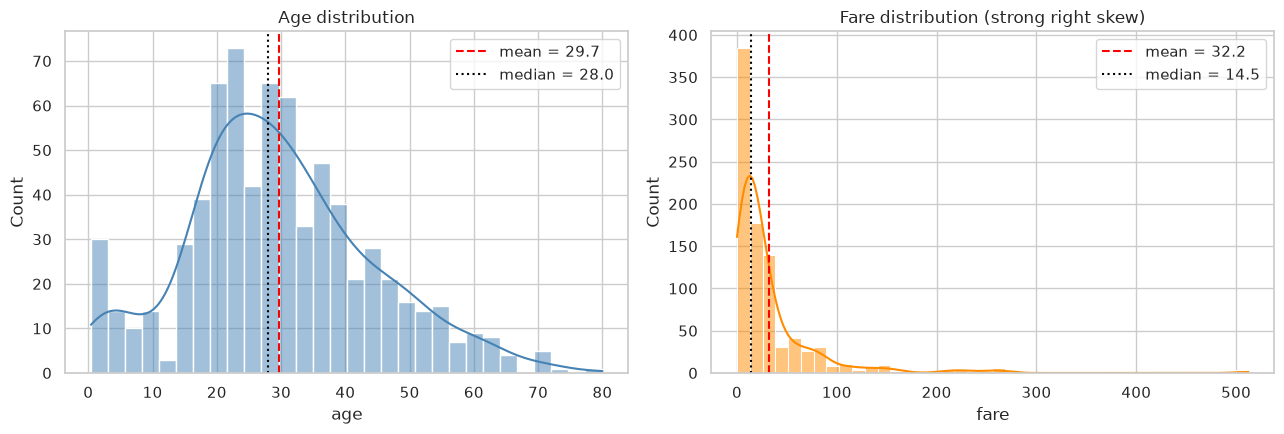

In [15]:
# Histograms with KDE for continuous variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="age", bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(df["age"].mean(), color="red", ls="--", label=f"mean = {df['age'].mean():.1f}")
axes[0].axvline(df["age"].median(), color="black", ls=":", label=f"median = {df['age'].median():.1f}")
axes[0].set_title("Age distribution")
axes[0].legend()

sns.histplot(data=df, x="fare", bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].axvline(df["fare"].mean(), color="red", ls="--", label=f"mean = {df['fare'].mean():.1f}")
axes[1].axvline(df["fare"].median(), color="black", ls=":", label=f"median = {df['fare'].median():.1f}")
axes[1].set_title("Fare distribution (strong right skew)")
axes[1].legend()
plt.tight_layout()
plt.show()

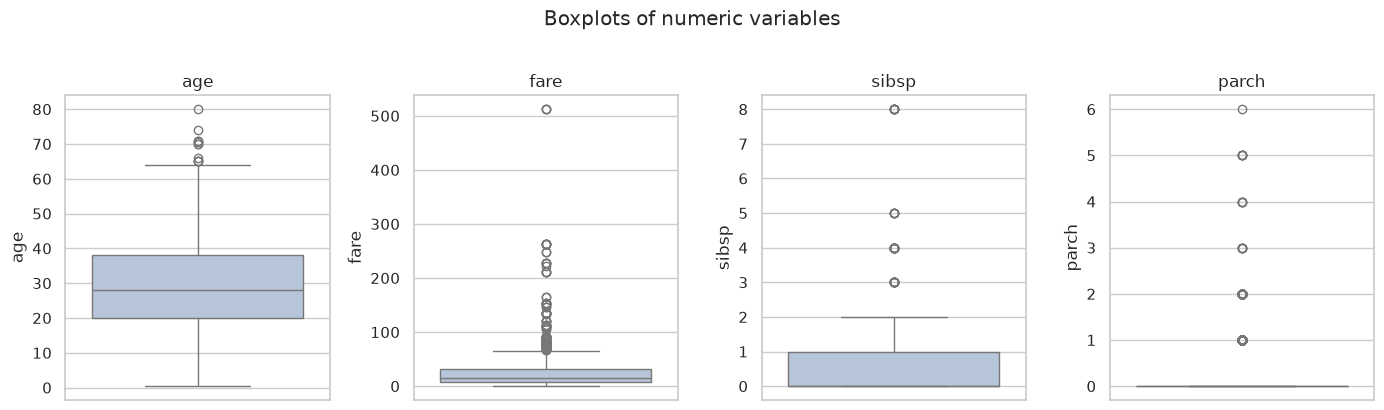

In [16]:
# Boxplots expose outliers via the 1.5*IQR rule
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# Count outliers per variable using the IQR rule
def iqr_outliers(s: pd.Series) -> pd.Series:
    """Return a boolean mask of values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outlier_report = pd.DataFrame({
    col: {"n_outliers": int(iqr_outliers(df[col].dropna()).sum()),
          "pct": round(iqr_outliers(df[col].dropna()).mean() * 100, 2)}
    for col in numeric_cols
}).T
outlier_report

,n_outliers,pct
age,11.0,1.54
fare,116.0,13.02
sibsp,46.0,5.16
parch,213.0,23.91


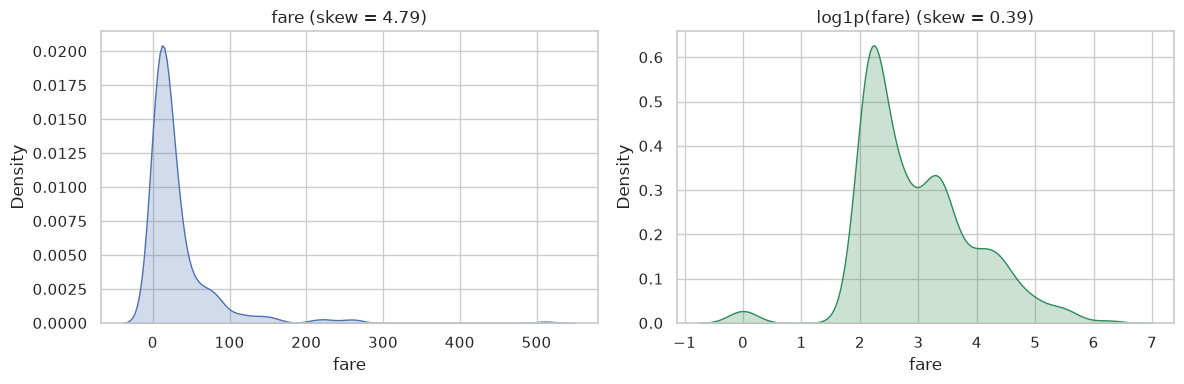

In [18]:
# KDE of fare on the original vs log scale: log1p tames the skew
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(df["fare"], fill=True, ax=axes[0])
axes[0].set_title(f"fare (skew = {df['fare'].skew():.2f})")
sns.kdeplot(np.log1p(df["fare"]), fill=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(fare) (skew = {np.log1p(df['fare']).skew():.2f})")
plt.tight_layout()
plt.show()

In [19]:
# Central tendency, dispersion and shape statistics
stats = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median(),
    "mode": df[numeric_cols].mode().iloc[0],
    "std": df[numeric_cols].std(),
    "min": df[numeric_cols].min(),
    "max": df[numeric_cols].max(),
    "skewness": df[numeric_cols].skew(),
    "kurtosis": df[numeric_cols].kurt(),  # excess kurtosis (normal = 0)
}).round(3)
stats

,mean,median,mode,std,min,max,skewness,kurtosis
age,29.699,28.000,24.00,14.526,0.42,80.000,0.389,0.178
fare,32.204,14.454,8.05,49.693,0.00,512.329,4.787,33.398
sibsp,0.523,0.000,0.00,1.103,0.00,8.000,3.695,17.880
parch,0.382,0.000,0.00,0.806,0.00,6.000,2.749,9.778


### Interpretando as estatísticas

- **Média vs mediana:** em `fare`, a média (~32) é mais que o dobro da mediana (~14) — sinal clássico de **assimetria à direita** causada por poucas tarifas muito altas (até 512). Para resumir variáveis assim, a **mediana** é mais representativa.
- **Moda:** a moda de `sibsp` e `parch` é 0 — a maioria viajava sem irmãos/cônjuges ou pais/filhos a bordo.
- **Skewness (assimetria):** ≈0 indica simetria; >1 indica cauda longa à direita. `age` é quase simétrica (~0,39); `fare` (~4,8) é extremamente assimétrica.
- **Kurtosis (curtose em excesso):** mede o "peso" das caudas em relação à normal (=0). `fare` (~33) tem caudas muito pesadas, coerentes com os outliers do boxplot.
- **Transformação logarítmica:** `log1p(fare)` reduz a assimetria drasticamente — informação útil para modelos sensíveis à escala (ex.: regressão linear).

> 💡 **Nota de aprendizado:** "outlier" estatístico não é sinônimo de erro. As tarifas de 512 libras são reais (suítes de primeira classe). Removê-las apagaria justamente os passageiros mais ricos.

In [20]:
# Frequency tables (absolute and relative) for categorical variables
for col in ["survived", "pclass", "sex", "embarked", "who"]:
    freq = pd.concat(
        [df[col].value_counts(dropna=False), df[col].value_counts(normalize=True, dropna=False).mul(100).round(1)],
        axis=1, keys=["count", "pct"],
    )
    print(f"--- {col} ---\n{freq}\n")

--- survived ---
          count   pct
survived             
0           549  61.6
1           342  38.4

--- pclass ---
        count   pct
pclass             
3         491  55.1
1         216  24.2
2         184  20.7

--- sex ---
        count   pct
sex                
male      577  64.8
female    314  35.2

--- embarked ---
          count   pct
embarked             
S           644  72.3
C           168  18.9
Q            77   8.6
NaN           2   0.2

--- who ---
       count   pct
who               
man      537  60.3
woman    271  30.4
child     83   9.3



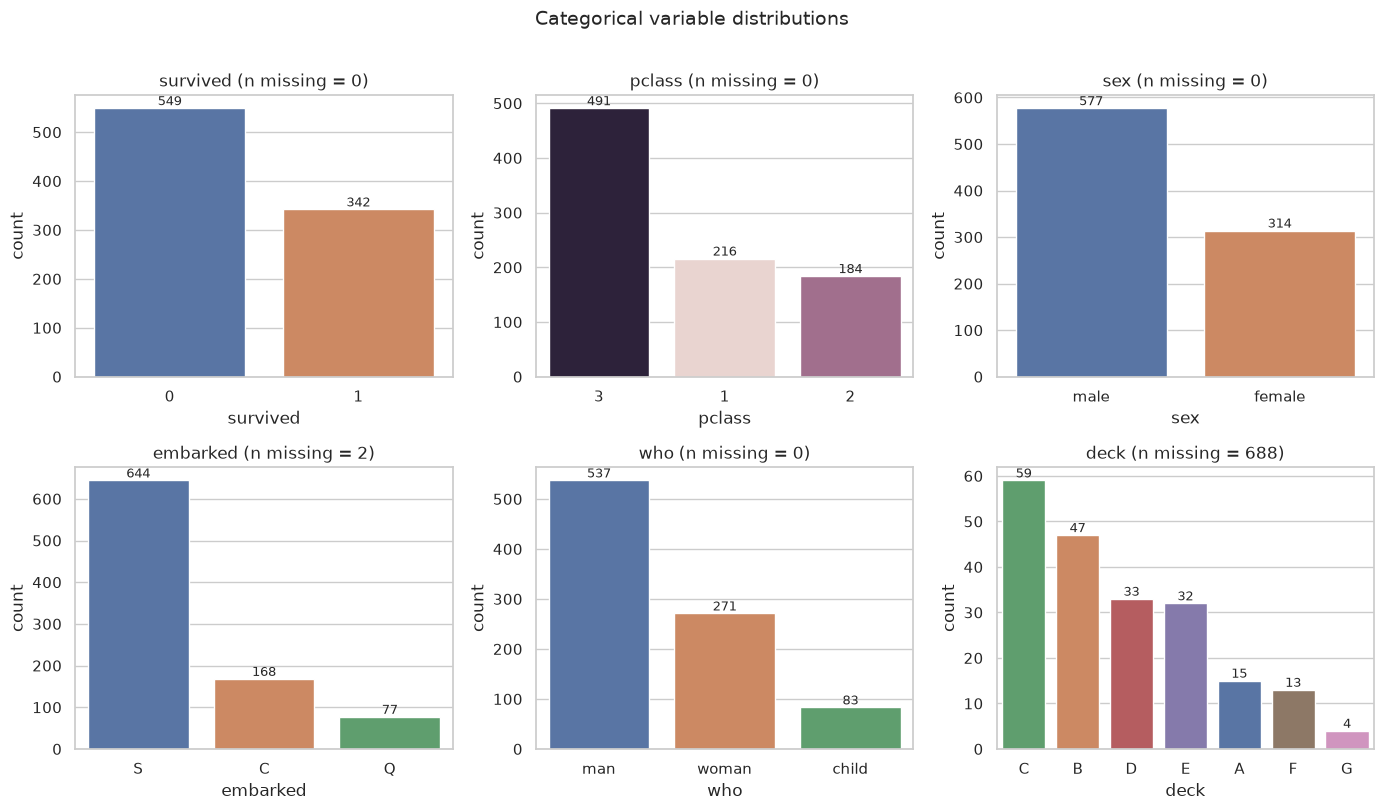

In [21]:
# Bar plots for categorical variables
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, ["survived", "pclass", "sex", "embarked", "who", "deck"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, hue=col, legend=False)
    ax.set_title(f"{col} (n missing = {df[col].isnull().sum()})")
    for container in ax.containers:
        ax.bar_label(container, fontsize=9)
plt.suptitle("Categorical variable distributions", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
# Mode of each categorical variable and its share of observations
cat_modes = pd.DataFrame({
    "mode": [df[c].mode().iloc[0] for c in categorical_cols],
    "mode_share_pct": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in categorical_cols],
}, index=categorical_cols)
cat_modes

,mode,mode_share_pct
survived,0,61.6
pclass,3,55.1
sex,male,64.8
embarked,S,72.4
who,man,60.3
deck,C,29.1
alone,True,60.3


> 💡 **Nota de aprendizado (univariada categórica):**
> - **Desbalanceamento do alvo:** apenas ~38% sobreviveram. Um modelo que sempre previsse "não sobreviveu" já teria ~62% de acurácia — esse é o *baseline* a superar.
> - **Classe:** a 3ª classe concentra ~55% dos passageiros.
> - **Sexo:** ~65% eram homens.
> - **Embarque:** ~72% embarcaram em Southampton (S).

## 5. Análise Bivariada

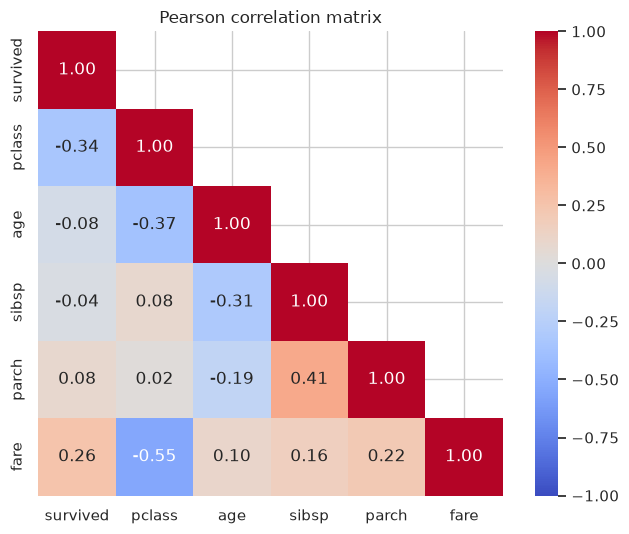

In [23]:
# Pearson correlation matrix for numeric (and binary) variables
corr_cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr = df[corr_cols].corr(method="pearson")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

In [24]:
# Spearman (rank-based) is more robust to skew and outliers such as 'fare'
spearman = df[corr_cols].corr(method="spearman")
comparison = pd.DataFrame({
    "pearson_vs_survived": corr["survived"],
    "spearman_vs_survived": spearman["survived"],
}).drop("survived").round(3).sort_values("spearman_vs_survived")
comparison

,pearson_vs_survived,spearman_vs_survived
pclass,-0.338,-0.340
age,-0.077,-0.053
sibsp,-0.035,0.089
parch,0.082,0.138
fare,0.257,0.324


> 💡 **Nota de aprendizado:** **Pearson** mede relação *linear* e é sensível a outliers; **Spearman** usa postos (*ranks*) e capta relações monotônicas. Em `fare`, Spearman com `survived` é maior que Pearson porque reduz a influência das tarifas extremas. Também é visível a forte correlação negativa entre `pclass` e `fare` (classe mais alta → tarifa maior) — um caso de **multicolinearidade** a considerar na modelagem.

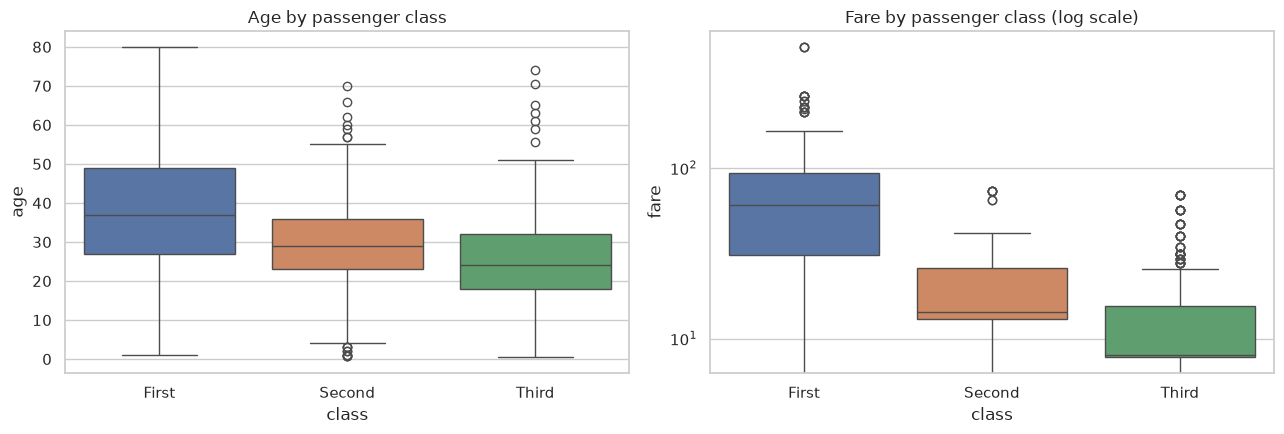

         age  fare
class             
First   37.0  60.3
Second  29.0  14.2
Third   24.0   8.0


In [25]:
# Categorical vs numeric: age and fare distributions by class
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="class", y="age", hue="class", legend=False, ax=axes[0])
axes[0].set_title("Age by passenger class")
sns.boxplot(data=df, x="class", y="fare", hue="class", legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Fare by passenger class (log scale)")
plt.tight_layout()
plt.show()

print(df.groupby("class", observed=True)[["age", "fare"]].median().round(1))

          n  survivors  survival_rate
sex                                  
female  314        233          0.742
male    577        109          0.189


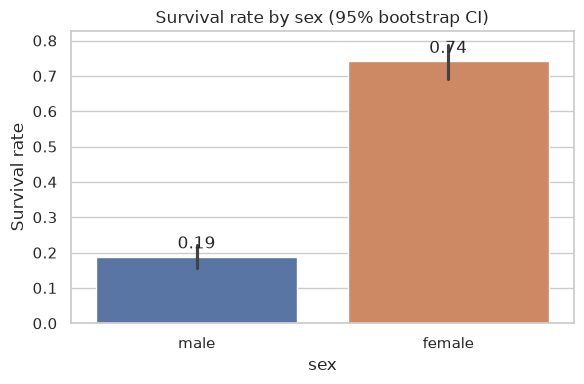

In [26]:
# Survival by sex: rate and counts
sex_surv = df.groupby("sex")["survived"].agg(n="count", survivors="sum", survival_rate="mean").round(3)
print(sex_surv)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=df, x="sex", y="survived", hue="sex", legend=False, ax=ax, errorbar=("ci", 95))
ax.set_ylabel("Survival rate")
ax.set_title("Survival rate by sex (95% bootstrap CI)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

survived    0    1  All
class                  
First      80  136  216
Second     97   87  184
Third     372  119  491
All       549  342  891

Survival rate by class and sex:
sex     female   male
class                
First    0.968  0.369
Second   0.921  0.157
Third    0.500  0.135


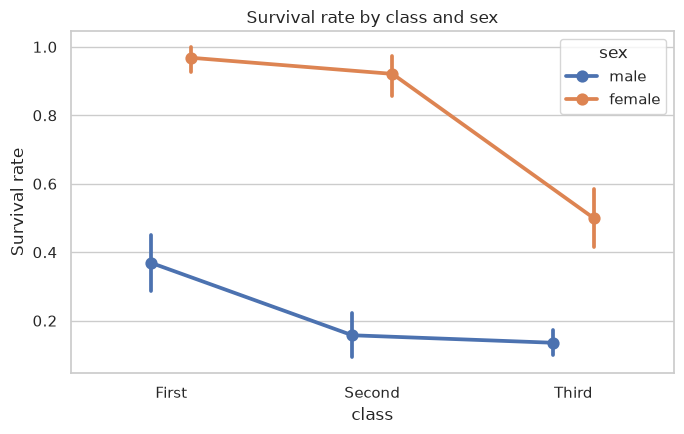

In [27]:
# Survival by class, and the class x sex interaction
print(pd.crosstab(df["class"], df["survived"], margins=True))
print("\nSurvival rate by class and sex:")
pivot = df.pivot_table(index="class", columns="sex", values="survived", aggfunc="mean", observed=True).round(3)
print(pivot)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.pointplot(data=df, x="class", y="survived", hue="sex", ax=ax, dodge=0.2)
ax.set_ylabel("Survival rate")
ax.set_title("Survival rate by class and sex")
plt.tight_layout()
plt.show()

             n  survival_rate
age_group                    
0-12        69          0.580
13-18       70          0.429
19-30      270          0.356
31-45      202          0.426
46-60       81          0.407
61-80       22          0.227


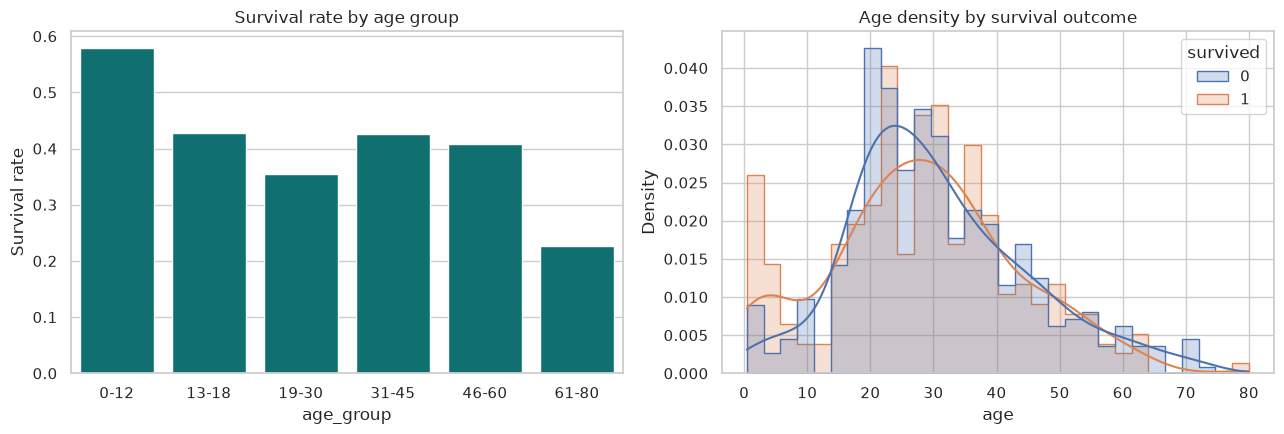

In [28]:
# Survival by age: binned age groups and overlaid distributions
age_bins = [0, 12, 18, 30, 45, 60, 80]
age_labels = ["0-12", "13-18", "19-30", "31-45", "46-60", "61-80"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

age_surv = df.groupby("age_group", observed=True)["survived"].agg(n="count", survival_rate="mean").round(3)
print(age_surv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x="age_group", y="survived", ax=axes[0], color="teal", errorbar=None)
axes[0].set_title("Survival rate by age group")
axes[0].set_ylabel("Survival rate")
sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Age density by survival outcome")
plt.tight_layout()
plt.show()

               n  survival_rate
family_size                    
1            537          0.304
2            161          0.553
3            102          0.578
4             29          0.724
5             15          0.200
6             22          0.136
7             12          0.333
8              6          0.000
11             7          0.000


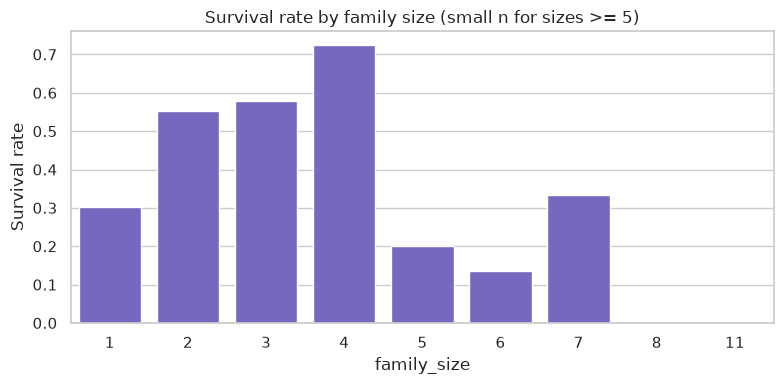

In [29]:
# Family size: does travelling alone or with a large family matter?
df["family_size"] = df["sibsp"] + df["parch"] + 1
fam = df.groupby("family_size")["survived"].agg(n="count", survival_rate="mean").round(3)
print(fam)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="family_size", y="survived", ax=ax, color="slateblue", errorbar=None)
ax.set_title("Survival rate by family size (small n for sizes >= 5)")
ax.set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

> 💡 **Nota de aprendizado (bivariada):**
> - **Sexo** é a variável com a associação mais forte: ~74% das mulheres sobreviveram contra ~19% dos homens — coerente com o protocolo "mulheres e crianças primeiro".
> - **Classe** também importa muito (1ª ≈63%, 3ª ≈24%), e a **interação classe × sexo** é marcante: mulheres de 1ª e 2ª classe sobreviveram em mais de 90%, enquanto as de 3ª classe ficaram perto de 50%.
> - **Idade:** crianças (0–12) tiveram a maior taxa de sobrevivência; a relação não é linear, o que explica a correlação de Pearson próxima de zero entre `age` e `survived`.
> - **Família:** famílias pequenas (2–4 pessoas) sobreviveram mais que pessoas sozinhas ou famílias grandes — mas grupos com 5+ pessoas têm *n* pequeno, então a estimativa é instável.
>
> Correlação próxima de zero **não** significa ausência de relação; significa ausência de relação *linear*. Por isso combinamos números com gráficos.

## 6. Visualizações Avançadas

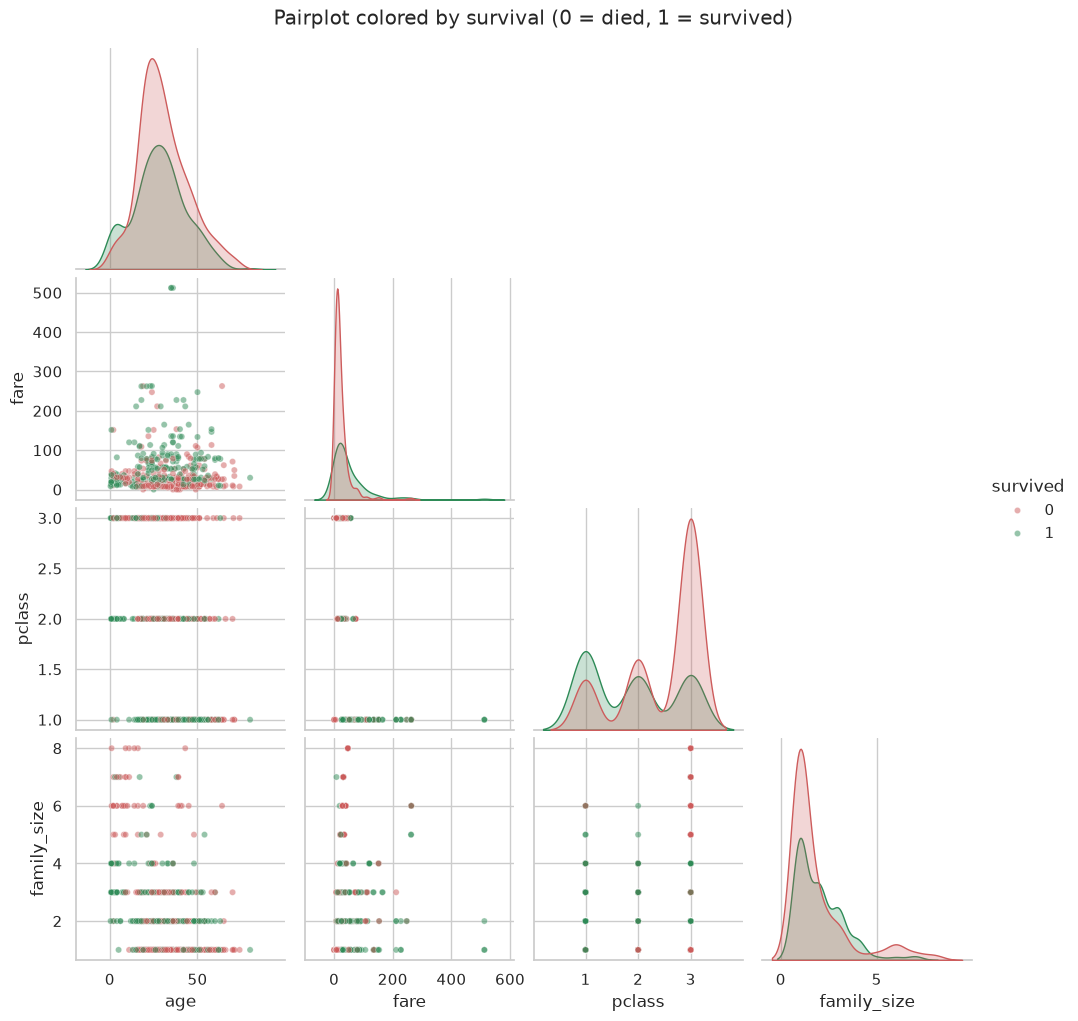

In [30]:
# Pairplot: all pairwise relationships colored by survival
pair_df = df[["survived", "age", "fare", "pclass", "family_size"]].dropna()
g = sns.pairplot(pair_df, hue="survived", diag_kind="kde", corner=True,
                 plot_kws={"alpha": 0.5, "s": 20}, palette={0: "indianred", 1: "seagreen"})
g.figure.suptitle("Pairplot colored by survival (0 = died, 1 = survived)", y=1.02)
plt.show()

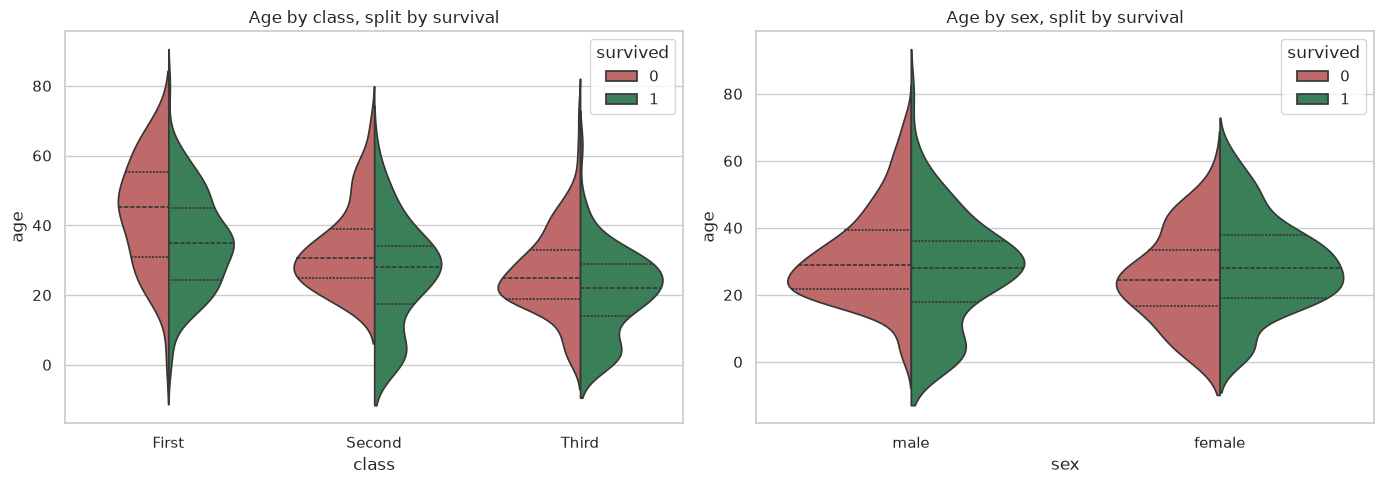

In [31]:
# Violin plots combine a boxplot with a mirrored KDE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=df, x="class", y="age", hue="survived", split=True, inner="quart",
               palette={0: "indianred", 1: "seagreen"}, ax=axes[0])
axes[0].set_title("Age by class, split by survival")
sns.violinplot(data=df, x="sex", y="age", hue="survived", split=True, inner="quart",
               palette={0: "indianred", 1: "seagreen"}, ax=axes[1])
axes[1].set_title("Age by sex, split by survival")
plt.tight_layout()
plt.show()

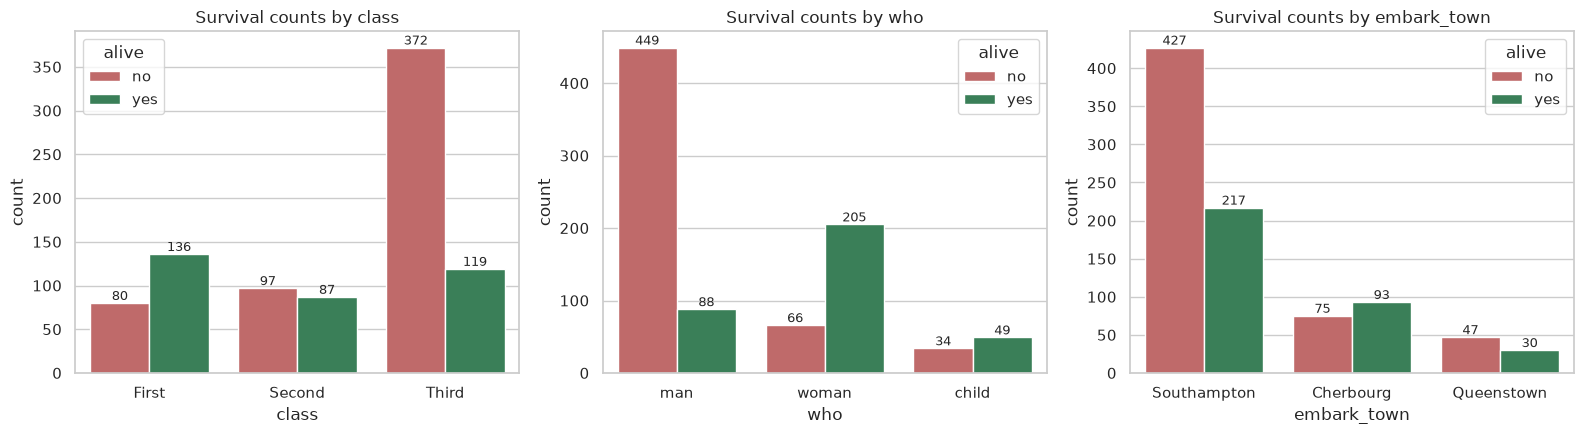

In [32]:
# Countplots with hue: survival counts across several categorical variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["class", "who", "embark_town"]):
    sns.countplot(data=df, x=col, hue="alive", palette={"no": "indianred", "yes": "seagreen"}, ax=ax)
    ax.set_title(f"Survival counts by {col}")
    for container in ax.containers:
        ax.bar_label(container, fontsize=9)
plt.tight_layout()
plt.show()

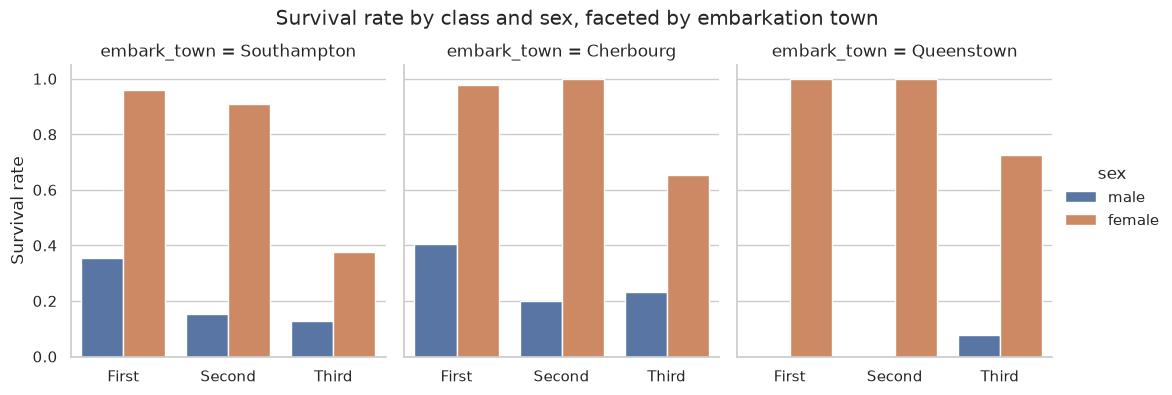

class        First  Second  Third
embark_town                      
Cherbourg       85      17     66
Queenstown       2       3     72
Southampton    127     164    353


In [33]:
# Faceted view: survival by class and sex across embarkation towns
g = sns.catplot(data=df, x="class", y="survived", hue="sex", col="embark_town",
                kind="bar", errorbar=None, height=4, aspect=0.9)
g.set_axis_labels("", "Survival rate")
g.figure.suptitle("Survival rate by class and sex, faceted by embarkation town", y=1.04)
plt.show()

print(df.groupby(["embark_town", "class"], observed=True).size().unstack(fill_value=0))

> 💡 **Nota de aprendizado:** a faceta por porto de embarque mostra que **Cherbourg** tem taxa de sobrevivência maior — mas a tabela de contagem revela que Cherbourg recebeu proporcionalmente mais passageiros de 1ª classe. Isso é um exemplo de **variável de confusão** (*confounding*): o porto parece importar, porém parte do efeito provavelmente vem da composição de classe. Gráficos condicionados ajudam a não tirar conclusões apressadas.

In [34]:
# Compact, reusable EDA summary table for the most informative groupings
summary_rows = []
for col in ["sex", "class", "who", "age_group", "alone", "embark_town"]:
    grp = df.groupby(col, observed=True)["survived"].agg(["count", "mean"])
    for level, row in grp.iterrows():
        summary_rows.append({"variable": col, "level": str(level), "n": int(row["count"]),
                             "survival_rate": round(row["mean"], 3)})
eda_summary = pd.DataFrame(summary_rows)
eda_summary["lift_vs_overall"] = (eda_summary["survival_rate"] / df["survived"].mean()).round(2)
eda_summary.sort_values("survival_rate", ascending=False).head(10)

,variable,level,n,survival_rate,lift_vs_overall
7,who,woman,271,0.756,1.97
0,sex,female,314,0.742,1.93
2,class,First,216,0.630,1.64
5,who,child,83,0.590,1.54
8,age_group,0-12,69,0.580,1.51
16,embark_town,Cherbourg,168,0.554,1.44
14,alone,False,354,0.506,1.32
3,class,Second,184,0.473,1.23
9,age_group,13-18,70,0.429,1.12
11,age_group,31-45,202,0.426,1.11


In [35]:
# Remove helper columns so the original dataset structure is preserved
df = df.drop(columns=["age_group", "family_size"])
print(f"Final shape: {df.shape}  (original: 891 x 15)")

Final shape: (891, 15)  (original: 891 x 15)


## 7. Insights e Conclusões

### Principais achados
1. **Estrutura:** 891 passageiros × 15 colunas, com várias colunas redundantes (`alive`/`survived`, `class`/`pclass`, `embark_town`/`embarked`) e derivadas (`who`, `adult_male`, `alone`) — risco de *data leakage* se usadas sem cuidado.
2. **Qualidade:** `deck` tem ~77% de ausentes (padrão associado à classe, sugerindo MNAR/MAR); `age` tem ~20% (indícios de MAR em relação à classe); `embarked` tem apenas 2.
3. **Alvo desbalanceado:** ~38% de sobreviventes → *baseline* de ~62% de acurácia.
4. **Sexo** é o fator mais associado à sobrevivência (≈74% mulheres vs ≈19% homens).
5. **Classe socioeconômica** importa (1ª ≈63% vs 3ª ≈24%) e **interage** com o sexo.
6. **Idade** tem relação não linear: crianças sobreviveram mais; o coeficiente de Pearson esconde esse padrão.
7. **`fare`** é muito assimétrica (skew ≈4,8); `log1p` a aproxima da simetria; outliers são reais, não erros.
8. **Porto de embarque** parece relevante, mas é provavelmente confundido pela composição de classe.

### Perguntas para análise futura
- As diferenças de sobrevivência por sexo e classe são **estatisticamente significativas**? (teste qui-quadrado, intervalos de confiança — Fase 3)
- Qual estratégia de imputação de `age` (mediana global, por grupo, KNN, imputação múltipla) gera menos viés?
- Tamanho de família tem efeito real ou é ruído das categorias pequenas?
- Quanto do efeito de `embark_town` sobrevive após controlar por `class`?
- Que *features* derivadas (títulos de nome, tamanho de família, flag `has_deck`) seriam úteis num modelo?

### Conexão com os próximos passos
- **Fase 2 (próximos dias):** aprofundar tratamento de missing, detecção de outliers, *feature engineering* e EDA em datasets maiores e textuais.
- **Fase 3 — Estatística:** transformar as hipóteses deste caderno em testes formais.
- **Fase 4 — Machine Learning:** usar os achados para escolher *features*, evitar vazamento e definir o *baseline*.
- **Ponte com NLP e educação:** o mesmo roteiro (estrutura → qualidade → univariada → bivariada) se aplica a *corpora* de aprendizes: distribuição de comprimento de textos, frequência de palavras, variação por nível de proficiência.

> **Limites deste caderno:** análise descritiva de um dataset histórico e público; nenhuma associação foi testada formalmente nem deve ser interpretada como causal.